# Exploratory Data Analysis - NTSB aviation cases

This notebook performs EDA of aviation cases from NTSB public API.

The analysis focuses on exploring potential input data and labels for developing a model, which will be able to infer events leading to and/or causes of an aviation incident.

## Conclusions
`analysisNarrative` is chosen as input for the model
Characteristics:
- It's available in 83.5% of the dataset
- It's available mostly for completed investigations (90.9% of Completed cases, 1.3%/0% of N/A and Ongoing cases)
- The median length is 112 words (maximum 5879), much shorter than the factual narrative

`Events` are chosen as labels for learning.
- Have the best availability (37.0%)
- 28605 of 29017 cases have exactly one defining event, so it fits multiclass classification
- In 79% of cases the defining event is the first event in the sequence
- Defining events fall into 36 CICTT occurrence categories, 34 of them have at least 20 cases

`Findings` could potentially be used as labels as well. 
Tier 1 findings have only 5 categories, while tier 2 have 21, the next tiers have too many distinct labels therefore are not suitable for multilabel classification.


- `Factual narrative` is very long (median 272 words), available only in 58.3% of cases -> not chosen
- `Preliminary analysis` is available only in 0.7% of cases -> not chosen
- `Probable Cause` has the median text length at only 23 words. Paired with findings it wouldn't pose a big challenge for the model.



## Setup and loading

In [1]:
import json
import re

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer

pd.set_option("display.max_colwidth", 200)
pd.set_option("display.width", 200)

In [2]:
with open("ntsb_cases.json", encoding="utf-8") as file:
    raw_cases = json.load(file)

In [3]:
print("Number of cases:", len(raw_cases))

Number of cases: 99670


In [4]:
cases_with_several_narratives = 0
cases_with_several_aircraft = 0
for case in raw_cases:
    narratives = case.get("narratives") or []
    aircraft_list = case.get("aircrafts") or []
    if len(narratives) > 1:
        cases_with_several_narratives += 1
    if len(aircraft_list) > 1:
        cases_with_several_aircraft += 1

In [5]:
print("Cases with more than one narrative record:", cases_with_several_narratives)
print("Cases with more than one aircraft:", cases_with_several_aircraft)

Cases with more than one narrative record: 1225
Cases with more than one aircraft: 1492


In [6]:
def clean_text(value):
    if isinstance(value, str) and value.strip() != "":
        return value.strip()
    return None

In [7]:
TEXT_FIELDS = {
    "probableCause": "probableCause",
    "factualNarrative": "concatenatedFactualNarrative",
    "analysisNarrative": "analysisNarrative",
    "prelimNarrative": "prelimNarrative",
}
FINDING_COLUMNS = ["findingNumber", "findingCode", "findingDescription", "inProbableCause",
                   "tier1Name", "tier2Name", "tier3Name", "tier4Name", "modifierName"]
EVENT_COLUMNS = ["eventNumber", "sequenceNumber", "eventCode", "eventTier1Name", "eventTier2Name",
                 "cicttPhaseSOEGroup", "cicttEventSOEGroup", "isDefiningEvent"]
CASE_COLUMNS = ["mKey", "ntsbNumber", "eventDate", "eventType", "completionStatus",
                "investigationClass", "highestInjuryLevel", "caseType"]

In [8]:
case_rows = []
finding_rows = []
event_rows = []

for case in raw_cases:
    narratives = case.get("narratives") or []
    if len(narratives) > 0:
        narrative = narratives[0]
    else:
        narrative = {}

    aircraft_list = case.get("aircrafts") or []

    case_row = {}
    for column in CASE_COLUMNS:
        case_row[column] = case.get(column)
    case_row["numberOfAircraft"] = len(aircraft_list)
    for field_name, json_key in TEXT_FIELDS.items():
        case_row[field_name] = clean_text(narrative.get(json_key))
    case_rows.append(case_row)

    for aircraft in aircraft_list:
        for finding in aircraft.get("findings") or []:
            finding_row = {"mKey": case["mKey"], "aircraftNumber": aircraft.get("aircraftNumber")}
            for column in FINDING_COLUMNS:
                finding_row[column] = finding.get(column)
            finding_rows.append(finding_row)

        for event in aircraft.get("events") or []:
            event_row = {"mKey": case["mKey"], "aircraftNumber": aircraft.get("aircraftNumber")}
            for column in EVENT_COLUMNS:
                event_row[column] = event.get(column)
            event_rows.append(event_row)

In [9]:
cases_table = pd.DataFrame(case_rows)
findings_table = pd.DataFrame(finding_rows)
events_table = pd.DataFrame(event_rows)

In [10]:
events_table["isDefiningEvent"] = events_table["isDefiningEvent"].fillna(False).astype(bool)
events_table["phaseEvent"] = events_table["eventTier1Name"].fillna("") + " > " + events_table["eventTier2Name"].fillna("")

In [11]:
cause_finding_rows = findings_table[findings_table["inProbableCause"] == True]
defining_event_rows = events_table[events_table["isDefiningEvent"] == True]

cases_table["hasFindings"] = cases_table["mKey"].isin(findings_table["mKey"])
cases_table["hasCauseFindings"] = cases_table["mKey"].isin(cause_finding_rows["mKey"])
cases_table["hasEvents"] = cases_table["mKey"].isin(events_table["mKey"])
cases_table["hasDefiningEvent"] = cases_table["mKey"].isin(defining_event_rows["mKey"])

In [12]:
print("cases_table:", cases_table.shape)
print("findings_table:", findings_table.shape)
print("events_table:", events_table.shape)

cases_table: (99670, 17)
findings_table: (69955, 11)
events_table: (71574, 11)


In [13]:
cases_table.head(3)

,mKey,ntsbNumber,eventDate,eventType,completionStatus,investigationClass,highestInjuryLevel,caseType,numberOfAircraft,probableCause,factualNarrative,analysisNarrative,prelimNarrative,hasFindings,hasCauseFindings,hasEvents,hasDefiningEvent
0,132162,FTW80DA029,1980-01-01,Accident,Completed,NaN,Serious,NaN,1,NaN,---------------------------------------------------------------------------------------------------------------------------- FILE DATE LOCATION AIRCRAFT DATA INJURIES FLIGHT PILOT DATA F S M/N PUR...,NaN,NaN,False,False,True,False
1,131779,LAX80FUA07,1980-01-02,Accident,Completed,NaN,Minor,NaN,1,NaN,---------------------------------------------------------------------------------------------------------------------------- FILE DATE LOCATION AIRCRAFT DATA INJURIES FLIGHT PILOT DATA F S M/N PUR...,NaN,NaN,False,False,True,False
2,131823,CHI80FEE13,1980-01-02,Accident,Completed,NaN,Minor,NaN,1,NaN,---------------------------------------------------------------------------------------------------------------------------- FILE DATE LOCATION AIRCRAFT DATA INJURIES FLIGHT PILOT DATA F S M/N PUR...,NaN,NaN,False,False,True,False


In [14]:
findings_table.head(3)

,mKey,aircraftNumber,findingNumber,findingCode,findingDescription,inProbableCause,tier1Name,tier2Name,tier3Name,tier4Name,modifierName
0,68580,1,1,0204101546,Personnel issues-Action/decision-Action-Incorrect action performance-Student pilot - C,True,Personnel issues,Action/decision,Action,Incorrect action performance,Student/instructed pilot
1,68580,1,2,0106204111,Aircraft-Aircraft oper/perf/capability-Performance/control parameters-Landing flare-Incorrect use/operation - C,True,Aircraft,Aircraft oper/perf/capability,Performance/control parameters,Landing flare,Incorrect use/operation
2,68581,1,1,0403501570,Organizational issues-Support/oversight/monitoring-Safety programs-Adequacy of safety program-FAA/Regulator - F,True,Organizational issues,Support/oversight/monitoring,Safety programs,Adequacy of safety program,FAA/Regulator


In [15]:
events_table.head(3)

,mKey,aircraftNumber,eventNumber,sequenceNumber,eventCode,eventTier1Name,eventTier2Name,cicttPhaseSOEGroup,cicttEventSOEGroup,isDefiningEvent,phaseEvent
0,132162,1,1,1,NaN,Standing-engine(s) operating,NaN,Standing,NaN,False,Standing-engine(s) operating >
1,131779,1,1,1,NaN,Enroute-descent,NaN,Enroute,NaN,False,Enroute-descent >
2,131823,1,1,1,NaN,Landing-landing roll,NaN,Landing,NaN,False,Landing-landing roll >


In [16]:
print("Event date range:", cases_table["eventDate"].min(), "-", cases_table["eventDate"].max())

Event date range: 1980-01-01 - 2026-06-01


## 1. Availability of text fields, findings and events

In [17]:
TEXT_COLUMNS = ["probableCause", "factualNarrative", "analysisNarrative", "prelimNarrative"]

field_present = pd.DataFrame()
for column in TEXT_COLUMNS:
    field_present[column] = cases_table[column].notna()
field_present["findings (any)"] = cases_table["hasFindings"]
field_present["findings with inProbableCause=True"] = cases_table["hasCauseFindings"]
field_present["events (any)"] = cases_table["hasEvents"]
field_present["defining event"] = cases_table["hasDefiningEvent"]

In [18]:
availability = pd.DataFrame()
availability["cases"] = field_present.sum()
availability["% of cases"] = (field_present.mean() * 100).round(1)
availability.loc["total cases"] = [len(cases_table), 100.0]

In [19]:
availability

,cases,% of cases
probableCause,62203.0,62.4
factualNarrative,58125.0,58.3
analysisNarrative,83195.0,83.5
prelimNarrative,654.0,0.7
findings (any),23412.0,23.5
findings with inProbableCause=True,23162.0,23.2
events (any),36903.0,37.0
defining event,29017.0,29.1
total cases,99670.0,100.0


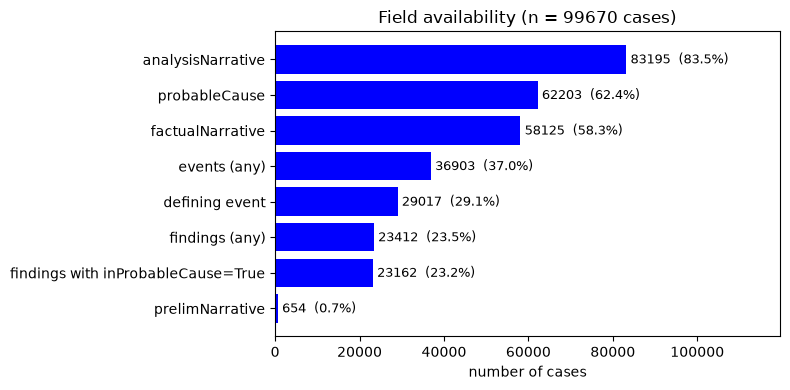

In [20]:
plot_data = availability.drop("total cases").sort_values("cases")
number_of_cases = len(cases_table)

figure, axis = plt.subplots(figsize=(8, 4))
axis.barh(plot_data.index, plot_data["cases"], color="blue")
for position, field_name in enumerate(plot_data.index):
    count = plot_data.loc[field_name, "cases"]
    percentage = plot_data.loc[field_name, "% of cases"]
    axis.text(count + number_of_cases * 0.01, position, f"{int(count)}  ({percentage:.1f}%)",
              va="center", fontsize=9)
axis.set_xlim(0, number_of_cases * 1.2)
axis.set_xlabel("number of cases")
axis.set_title(f"Field availability (n = {number_of_cases} cases)")
plt.tight_layout()
plt.show()

**Overlap between fields:** cases that have both the row field and the column field.

In [21]:
field_names = field_present.columns
overlap = pd.DataFrame(0, index=field_names, columns=field_names)
for row_field in field_names:
    for column_field in field_names:
        has_both = field_present[row_field] & field_present[column_field]
        overlap.loc[row_field, column_field] = has_both.sum()

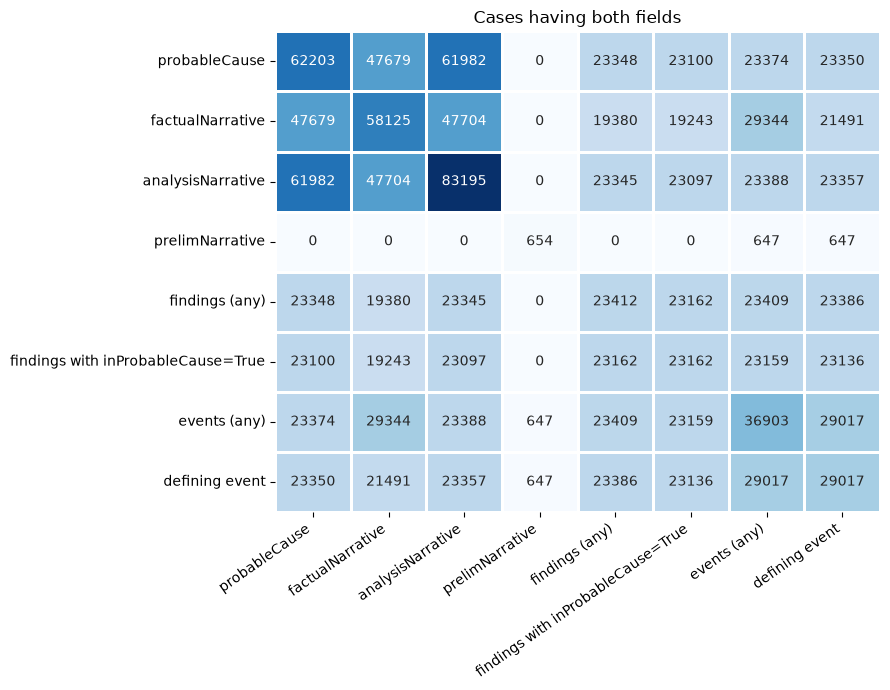

In [22]:
figure, axis = plt.subplots(figsize=(9, 7))
sns.heatmap(overlap, annot=True, fmt="d", cmap="Blues", cbar=False, linewidths=2, linecolor="white", ax=axis)
axis.set_title("Cases having both fields")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

## 2. Distribution of findings
Findings which appeared in probableCause have `inProbableCause = True`.

In [23]:
print("Total findings:", len(findings_table))
print("Cases with findings:", findings_table["mKey"].nunique())

Total findings: 69955
Cases with findings: 23412


In [24]:
cause_flag_counts = findings_table["inProbableCause"].value_counts(dropna=False).to_frame("findings")
cause_flag_counts["%"] = (cause_flag_counts["findings"] / cause_flag_counts["findings"].sum() * 100).round(1)
cause_flag_counts

,findings,%
inProbableCause,,
True,59159,84.6
False,10796,15.4


In [25]:
findings_per_case = pd.DataFrame()
findings_per_case["all_findings"] = findings_table.groupby("mKey").size()
findings_per_case["cause_findings"] = findings_table.groupby("mKey")["inProbableCause"].sum()

In [26]:
findings_per_case.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
all_findings,23412.0,2.99,1.53,1.0,2.0,3.0,4.0,36.0
cause_findings,23412.0,2.53,1.39,0.0,2.0,2.0,3.0,34.0


In [27]:
def tick_labels(values, limit):
    labels = [str(value) for value in values]
    labels[-1] = f"{limit}+"
    return labels

In [28]:
LIMIT = 8
limited_counts = findings_per_case.clip(upper=LIMIT)
grid = pd.crosstab(limited_counts["all_findings"], limited_counts["cause_findings"])
grid = grid.reindex(index=range(1, LIMIT + 1), columns=range(0, LIMIT + 1), fill_value=0)

In [29]:
hide_cell = pd.DataFrame(False, index=grid.index, columns=grid.columns)
for total_findings in grid.index:
    for cause_findings in grid.columns:
        if cause_findings > total_findings or grid.loc[total_findings, cause_findings] == 0:
            hide_cell.loc[total_findings, cause_findings] = True

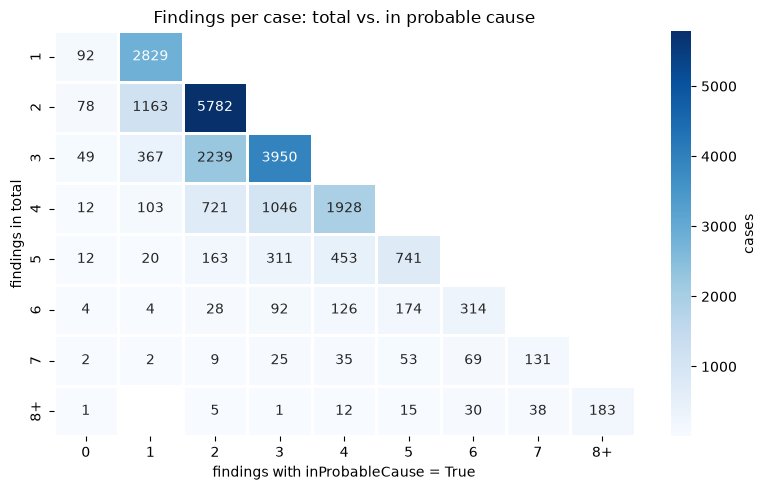

In [30]:
figure, axis = plt.subplots(figsize=(8, 5))
sns.heatmap(grid, mask=hide_cell, annot=True, fmt="d", cmap="Blues",
            cbar_kws={"label": "cases"}, linewidths=2, linecolor="white", ax=axis,
            xticklabels=tick_labels(grid.columns, LIMIT), yticklabels=tick_labels(grid.index, LIMIT))
axis.set_xlabel("findings with inProbableCause = True")
axis.set_ylabel("findings in total")
axis.set_title("Findings per case: total vs. in probable cause")
plt.tight_layout()
plt.show()

### Top categories per tier

In [31]:
def plot_top_values(table, column, flag_column, unit, number_of_values, title):
    top_values = table[column].value_counts().head(number_of_values).index
    top_rows = table[table[column].isin(top_values)]

    counts = pd.crosstab(top_rows[column], top_rows[flag_column] == True)
    counts = counts.reindex(index=top_values[::-1], columns=[True, False], fill_value=0)
    counts.columns = [f"{flag_column} = True", f"{flag_column} = False"]

    axis = counts.plot(kind="barh", stacked=True, color=["orange", "blue"], width=0.7,
                       figsize=(9, 0.3 * len(counts) + 2))
    totals = counts.sum(axis=1)
    for position, total in enumerate(totals):
        axis.text(total + totals.max() * 0.01, position, str(int(total)), va="center", fontsize=9)
    axis.set_xlabel(unit)
    axis.set_ylabel("")
    axis.legend(loc="lower right")
    axis.set_title(title)
    plt.tight_layout()
    plt.show()

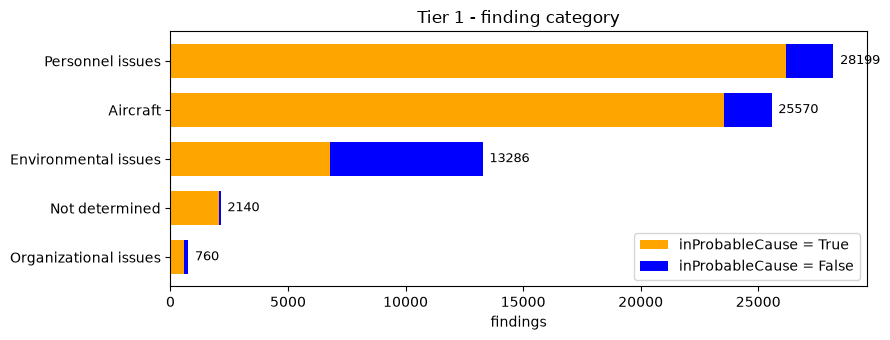

In [32]:
plot_top_values(
    table=findings_table,
    column="tier1Name",
    flag_column="inProbableCause",
    unit="findings",
    number_of_values=10,
    title="Tier 1 - finding category",
)

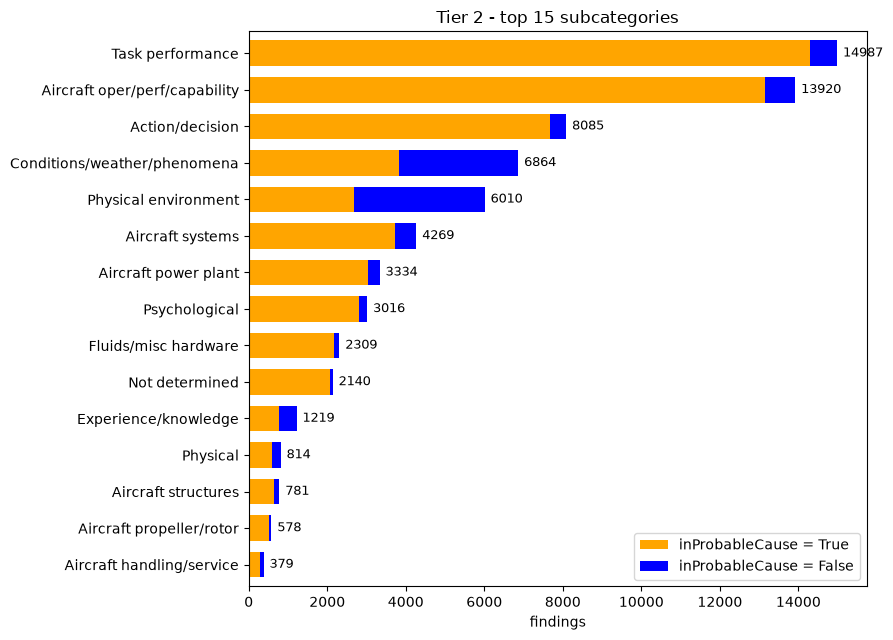

In [33]:
plot_top_values(
    table=findings_table,
    column="tier2Name",
    flag_column="inProbableCause",
    unit="findings",
    number_of_values=15,
    title="Tier 2 - top 15 subcategories",
)

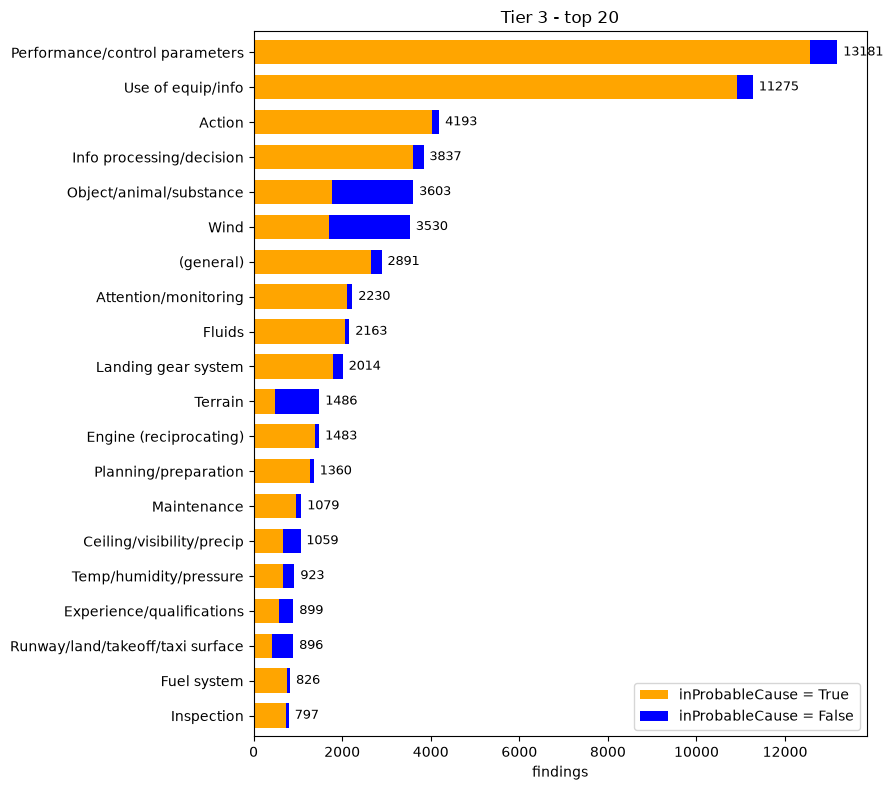

In [34]:
plot_top_values(
    table=findings_table,
    column="tier3Name",
    flag_column="inProbableCause",
    unit="findings",
    number_of_values=20,
    title="Tier 3 - top 20",
)

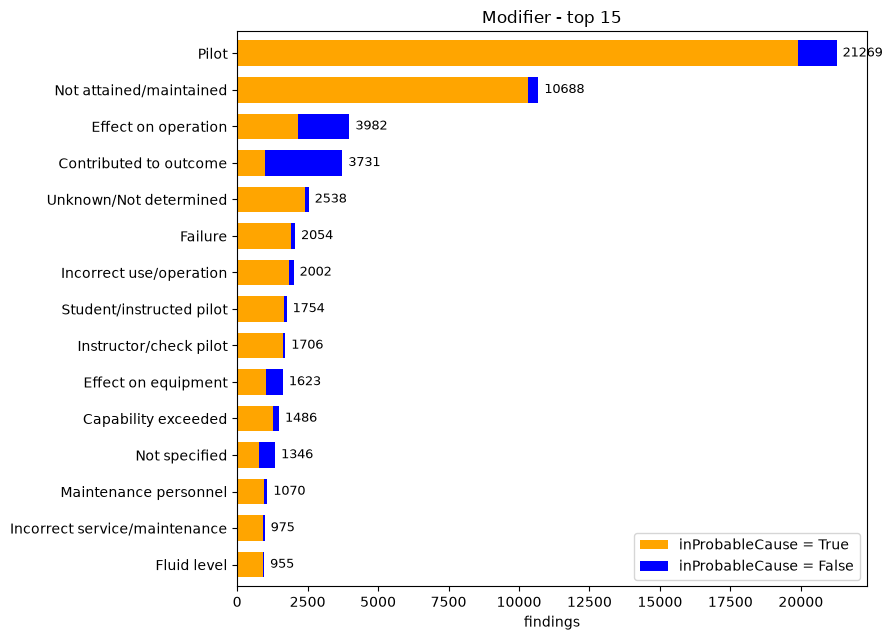

In [35]:
plot_top_values(
    table=findings_table,
    column="modifierName",
    flag_column="inProbableCause",
    unit="findings",
    number_of_values=15,
    title="Modifier - top 15",
)

In [36]:
grouped_by_description = findings_table.groupby("findingDescription")

description_summary = pd.DataFrame()
description_summary["findings"] = grouped_by_description.size()
description_summary["cases"] = grouped_by_description["mKey"].nunique()
description_summary["% in probable cause"] = (grouped_by_description["inProbableCause"].mean() * 100).round(0)
description_summary = description_summary.sort_values("findings", ascending=False).head(20)

In [37]:
description_summary

,findings,cases,% in probable cause
findingDescription,,,
Personnel issues-Task performance-Use of equip/info-Aircraft control-Pilot - C,5153,5153,100.0
Personnel issues-Task performance-Use of equip/info-Aircraft control-Pilot,2555,2554,94.0
Aircraft-Aircraft oper/perf/capability-Performance/control parameters-Directional control-Not attained/maintained - C,2340,2337,100.0
Not determined-Not determined-(general)-(general)-Unknown/Not determined - C,1466,1463,100.0
Personnel issues-Action/decision-Info processing/decision-Decision making/judgment-Pilot - C,1333,1331,100.0
Aircraft-Aircraft oper/perf/capability-Performance/control parameters-Directional control-Not attained/maintained,1114,1114,92.0
Personnel issues-Action/decision-Info processing/decision-Decision making/judgment-Pilot,1029,1025,89.0
Aircraft-Aircraft oper/perf/capability-Performance/control parameters-Airspeed-Not attained/maintained - C,975,975,100.0
Aircraft-Aircraft oper/perf/capability-Performance/control parameters-(general)-Not attained/maintained - C,763,762,100.0


### All categories per tier summary 

In [38]:
def finding_label(table, level):
    if level == 5:
        return table["findingDescription"]
    label = table["tier1Name"].fillna("")
    for tier in range(2, level + 1):
        label = label + " > " + table[f"tier{tier}Name"].fillna("")
    return label

In [39]:
LEVELS = {1: "tier 1", 2: "tier 1-2", 3: "tier 1-3", 4: "tier 1-4", 5: "full description"}
for level in LEVELS:
    findings_table[f"label_level_{level}"] = finding_label(findings_table, level)

cause_finding_rows = findings_table[findings_table["inProbableCause"] == True]

In [40]:
long_tail_rows = []
for level, level_name in LEVELS.items():
    label_counts = findings_table[f"label_level_{level}"].value_counts()
    cause_label_counts = cause_finding_rows[f"label_level_{level}"].value_counts()
    long_tail_rows.append({
        "level": level_name,
        "distinct labels": len(label_counts),
        "labels with < 5 findings": (label_counts < 5).sum(),
        "labels with >= 20 findings": (label_counts >= 20).sum(),
        "% findings covered by top 10": round(label_counts.head(10).sum() / label_counts.sum() * 100, 1),
        "distinct cause labels": len(cause_label_counts),
    })

In [41]:
pd.DataFrame(long_tail_rows).set_index("level")

,distinct labels,labels with < 5 findings,labels with >= 20 findings,% findings covered by top 10,distinct cause labels
level,,,,,
tier 1,5,0,5,100.0,5
tier 1-2,21,0,21,92.8,21
tier 1-3,130,7,95,68.9,128
tier 1-4,786,249,307,38.5,748
full description,6996,5371,443,25.0,6155


## 3. Distribution of events
Findings which appeared in probableCause have `isDefiningEvent = True` .

In [42]:
print("Total events:", len(events_table))
print("Cases with events:", events_table["mKey"].nunique())

Total events: 71574
Cases with events: 36903


In [43]:
defining_flag_counts = events_table["isDefiningEvent"].value_counts().to_frame("events")
defining_flag_counts["%"] = (defining_flag_counts["events"] / defining_flag_counts["events"].sum() * 100).round(1)

In [44]:
defining_flag_counts

,events,%
isDefiningEvent,,
False,42141,58.9
True,29433,41.1


In [45]:
events_per_case = pd.DataFrame()
events_per_case["all_events"] = events_table.groupby("mKey").size()
events_per_case["defining_events"] = events_table.groupby("mKey")["isDefiningEvent"].sum()

In [46]:
events_per_case.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
all_events,36903.0,1.94,1.18,1.0,1.0,1.0,3.0,9.0
defining_events,36903.0,0.80,0.43,0.0,1.0,1.0,1.0,3.0


In [47]:
defining_events_count = events_per_case["defining_events"].value_counts().sort_index().to_frame("cases")
defining_events_count.index.name = "defining events per case"

In [48]:
defining_events_count

,cases
defining events per case,
0,7886
1,28605
2,408
3,4


In [49]:
EVENT_LIMIT = 7
defining_position = defining_event_rows.groupby("mKey")["sequenceNumber"].min()

positions = pd.DataFrame()
positions["all_events"] = events_per_case["all_events"]
positions["defining_position"] = defining_position
positions = positions.dropna().astype(int).clip(upper=EVENT_LIMIT)

In [50]:
grid = pd.crosstab(positions["all_events"], positions["defining_position"])
grid = grid.reindex(index=range(1, EVENT_LIMIT + 1), columns=range(1, EVENT_LIMIT + 1), fill_value=0)

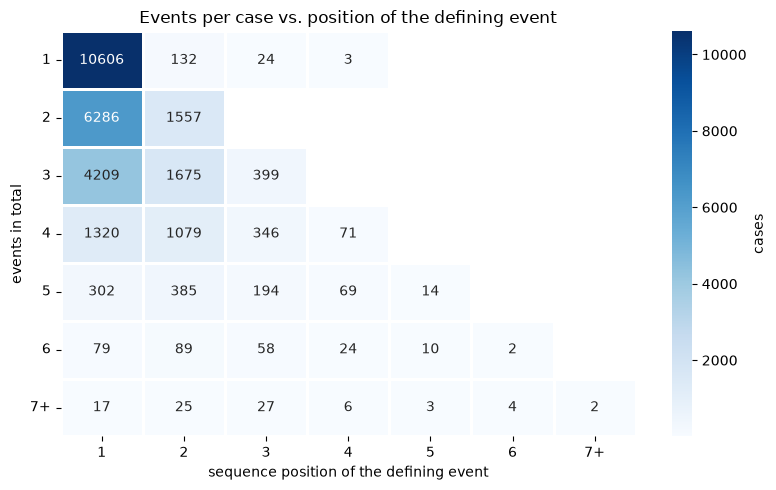

In [51]:
figure, axis = plt.subplots(figsize=(8, 5))
sns.heatmap(grid, mask=(grid == 0), annot=True, fmt="d", cmap="Blues",
            cbar_kws={"label": "cases"}, linewidths=2, linecolor="white", ax=axis,
            xticklabels=tick_labels(grid.columns, EVENT_LIMIT), yticklabels=tick_labels(grid.index, EVENT_LIMIT))
axis.set_xlabel("sequence position of the defining event")
axis.set_ylabel("events in total")
axis.tick_params(axis="y", rotation=0)
axis.set_title("Events per case vs. position of the defining event")
plt.tight_layout()
plt.show()

### Top categories

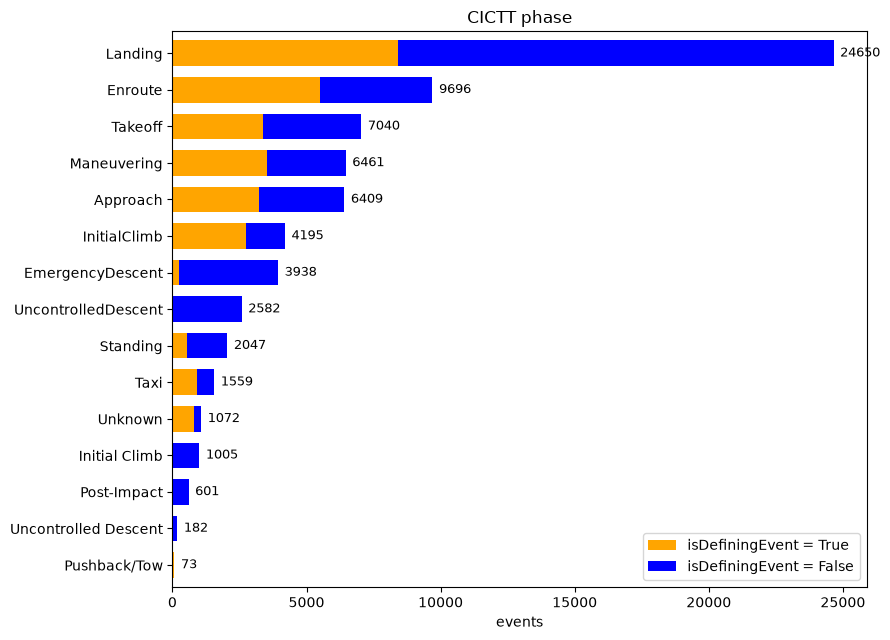

In [52]:
plot_top_values(
    table=events_table,
    column="cicttPhaseSOEGroup",
    flag_column="isDefiningEvent",
    unit="events",
    number_of_values=15,
    title="CICTT phase",
)

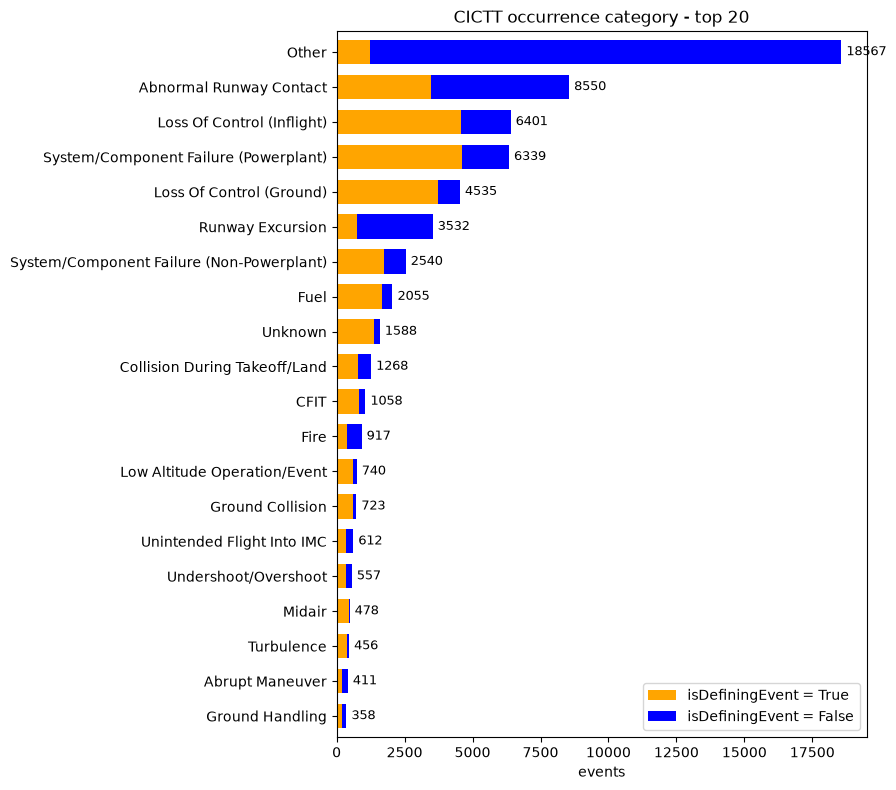

In [53]:
plot_top_values(
    table=events_table,
    column="cicttEventSOEGroup",
    flag_column="isDefiningEvent",
    unit="events",
    number_of_values=20,
    title="CICTT occurrence category - top 20",
)

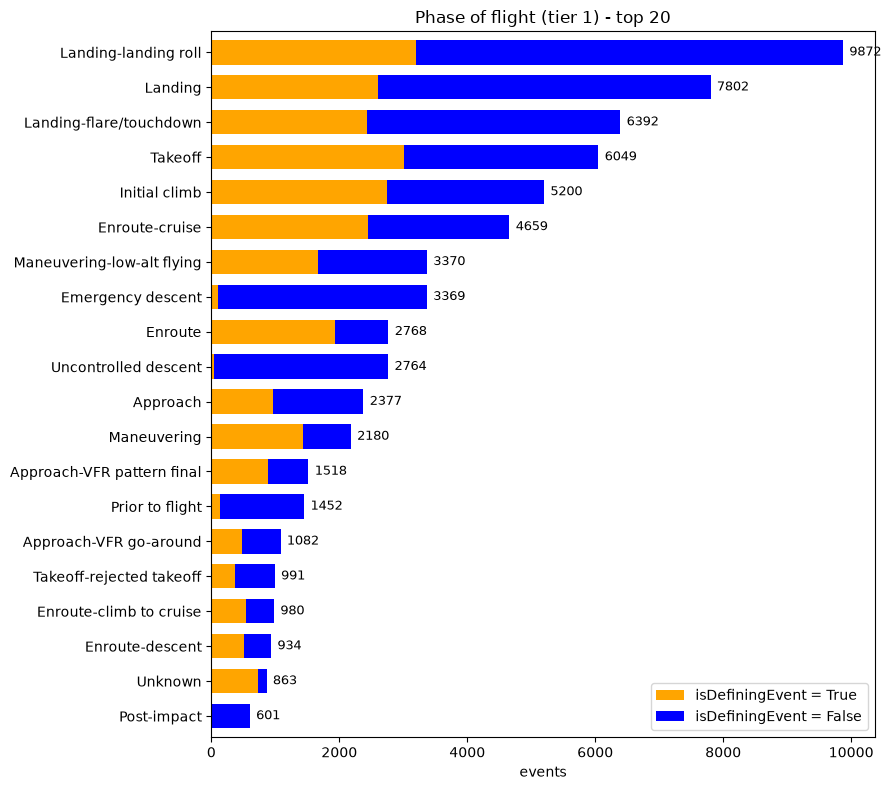

In [54]:
plot_top_values(
    table=events_table,
    column="eventTier1Name",
    flag_column="isDefiningEvent",
    unit="events",
    number_of_values=20,
    title="Phase of flight (tier 1) - top 20",
)

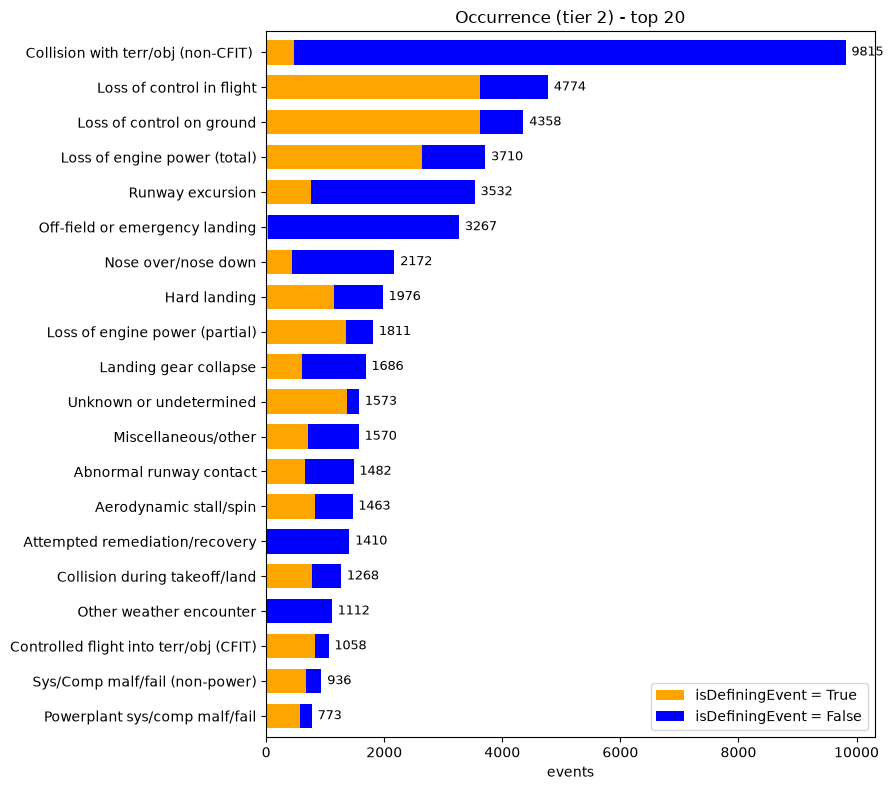

In [55]:
plot_top_values(
    table=events_table,
    column="eventTier2Name",
    flag_column="isDefiningEvent",
    unit="events",
    number_of_values=20,
    title="Occurrence (tier 2) - top 20",
)

In [56]:
grouped_by_phase_event = events_table.groupby("phaseEvent")

phase_event_summary = pd.DataFrame()
phase_event_summary["events"] = grouped_by_phase_event.size()
phase_event_summary["cases"] = grouped_by_phase_event["mKey"].nunique()
phase_event_summary["% defining"] = (grouped_by_phase_event["isDefiningEvent"].mean() * 100).round(0)
phase_event_summary = phase_event_summary.sort_values("events", ascending=False).head(20)

In [57]:
phase_event_summary

,events,cases,% defining
phaseEvent,,,
Uncontrolled descent > Collision with terr/obj (non-CFIT),2429,2415,0.0
Landing-landing roll > Loss of control on ground,2033,2033,84.0
Landing-landing roll > Runway excursion,1927,1926,21.0
Emergency descent > Off-field or emergency landing,1782,1782,0.0
Landing-landing roll > Collision with terr/obj (non-CFIT),1523,1522,2.0
Landing > Collision with terr/obj (non-CFIT),1285,1285,3.0
Landing-flare/touchdown >,1205,1203,0.0
Landing-flare/touchdown > Hard landing,1139,1138,65.0
Enroute-cruise >,1096,1079,0.0


### All categories per tier summary 

In [58]:
EVENT_LEVELS = {
    "CICTT phase": "cicttPhaseSOEGroup",
    "CICTT occurrence": "cicttEventSOEGroup",
    "phase (tier 1)": "eventTier1Name",
    "occurrence (tier 2)": "eventTier2Name",
    "phase > occurrence": "phaseEvent",
}

In [59]:
event_long_tail_rows = []
for level_name, column in EVENT_LEVELS.items():
    label_counts = events_table[column].value_counts()
    defining_label_counts = defining_event_rows[column].value_counts()
    event_long_tail_rows.append({
        "level": level_name,
        "distinct labels": len(label_counts),
        "labels with < 5 events": (label_counts < 5).sum(),
        "labels with >= 20 events": (label_counts >= 20).sum(),
        "% events covered by top 10": round(label_counts.head(10).sum() / label_counts.sum() * 100, 1),
        "distinct defining labels": len(defining_label_counts),
        "defining labels with >= 20 cases": (defining_label_counts >= 20).sum(),
    })

In [60]:
pd.DataFrame(event_long_tail_rows).set_index("level")

,distinct labels,labels with < 5 events,labels with >= 20 events,% events covered by top 10,distinct defining labels,defining labels with >= 20 cases
level,,,,,,
CICTT phase,18,1,16,95.8,14,12
CICTT occurrence,36,0,36,86.9,36,34
phase (tier 1),49,1,43,73.0,48,40
occurrence (tier 2),97,2,87,58.2,92,68
phase > occurrence,1618,727,443,21.7,1224,259


## 4. Text lengths

In [61]:
WORD_PATTERN = re.compile(r"[A-Za-z0-9]+(?:['’][A-Za-z]+)?")
SENTENCE_END_PATTERN = re.compile(r"[.!?]+(?:\s|$)")


def text_statistics(text):
    characters = len(text)
    words = len(WORD_PATTERN.findall(text))
    sentences = len(SENTENCE_END_PATTERN.findall(text))
    if sentences == 0:
        sentences = 1
    return pd.Series({"characters": characters, "words": words, "sentences": sentences})

In [62]:
LENGTH_FIELDS = ["probableCause", "factualNarrative", "analysisNarrative"]
lengths = {}
for field_name in LENGTH_FIELDS:
    lengths[field_name] = cases_table[field_name].dropna().apply(text_statistics)
lengths["findingDescription"] = findings_table["findingDescription"].dropna().apply(text_statistics)

In [63]:
summary_parts = {}
for field_name, field_lengths in lengths.items():
    summary_parts[field_name] = field_lengths.describe(percentiles=[0.25, 0.5, 0.75, 0.95]).T
length_summary = pd.concat(summary_parts)

In [64]:
length_summary.round(1)

count    mean     std   min     25%     50%     75%      95%      max
probableCause      characters  62203.0   163.1    93.8   1.0   101.0   144.0   203.0    329.9   2445.0
                   words       62203.0    25.6    14.7   0.0    16.0    23.0    32.0     52.0    356.0
                   sentences   62203.0     1.4     0.5   1.0     1.0     1.0     2.0      2.0     15.0
factualNarrative   characters  58125.0  3562.8  5062.1  15.0  1034.0  1655.0  3672.0  13267.0  79639.0
                   words       58125.0   582.4   839.2   2.0   154.0   272.0   605.0   2185.8  13277.0
                   sentences   58125.0    27.9    40.5   1.0     6.0    14.0    30.0    108.0    797.0
analysisNarrative  characters  83195.0   829.7   721.1   1.0   428.0   661.0  1003.0   1998.3  36500.0
                   words       83195.0   139.7   117.3   0.0    73.0   112.0   170.0    330.0   5879.0
                   sentences   83195.0     7.0     4.7   1.0     4.0     6.0     9.0     15.0    182.0
findingDescription characters  69953.0    90.5    16.3  27.0    78.0    89.0   104.0    117.0    139.0
                   words       69953.0    11.6     2.0   4.0    10.0    12.0    13.0     15.0     19.0
                   sentences   69953.0     1.0     0.0   1.0     1.0     1.0     1.0      1.0      1.0

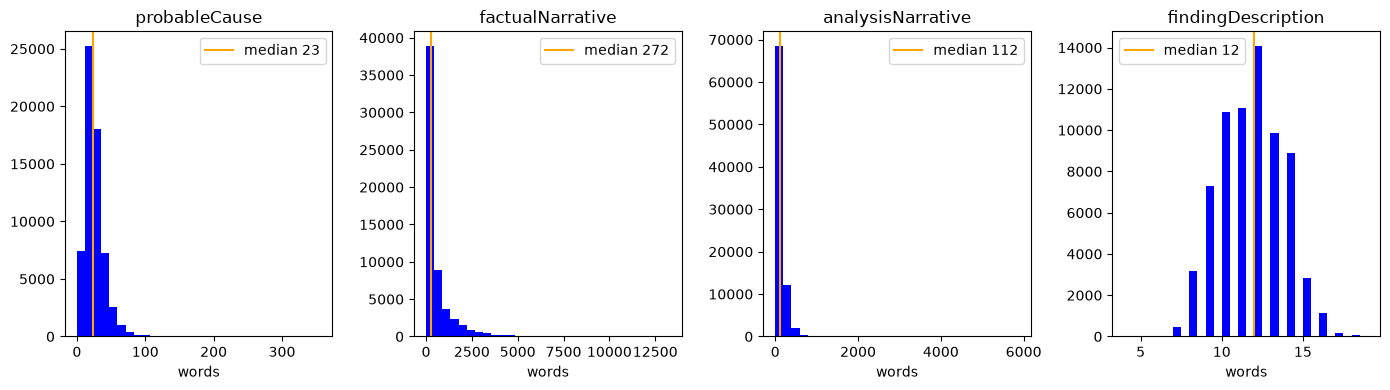

In [65]:
figure, axes = plt.subplots(1, 4, figsize=(14, 4))
for axis, field_name in zip(axes, lengths):
    word_counts = lengths[field_name]["words"]
    axis.hist(word_counts, bins=30, color="blue")
    axis.axvline(word_counts.median(), color="orange", label=f"median {word_counts.median():.0f}")
    axis.legend()
    axis.set_title(field_name)
    axis.set_xlabel("words")
plt.tight_layout()
plt.show()


### Shortest and longest texts

In [66]:
def shorten(text, maximum_length):
    if len(text) > maximum_length:
        return text[:maximum_length] + " …"
    return text

In [67]:
probable_causes = cases_table.dropna(subset=["probableCause"]).copy()
probable_causes["words"] = lengths["probableCause"]["words"]

In [68]:
print("===== SHORTEST probable causes =====")
for _, row in probable_causes.nsmallest(5, "words").iterrows():
    print(f"[{row['ntsbNumber']}, {row['words']} words] {row['probableCause']}\n")

===== SHORTEST probable causes =====
[ANC08WA096, 0 words] .

[DCA08WA100, 0 words] .

[DCA08WA094, 0 words] .

[DCA08WA096, 0 words] .

[DCA09WA008, 0 words] .



In [69]:
print("===== LONGEST probable causes =====")
for _, row in probable_causes.nlargest(2, "words").iterrows():
    print(f"[{row['ntsbNumber']}, {row['words']} words] {row['probableCause']}\n")

===== LONGEST probable causes =====
[DCA25MA108, 356 words] The Federal Aviation Administration’s (FAA) placement of a helicopter route in close proximity to a runway approach path; their failure to regularly review and evaluate helicopter routes and available data, and their failure to act on recommendations to mitigate the risk of a midair collision near Ronald Reagan Washington National Airport (DCA); as well as the air traffic system’s overreliance on visual separation in order to promote efficient traffic flow without consideration for the limitations of the see-and-avoid concept. Also causal was the lack of effective pilot-applied visual separation by the helicopter crew, which resulted in a midair collision. Additional causal factors were the tower team’s loss of situation awareness and degraded performance due to the high workload of the combined helicopter and local control positions and the absence of a risk assessment process to identify and mitigate real-time operational ri

In [70]:
factual_narratives = cases_table.dropna(subset=["factualNarrative"]).copy()
factual_narratives["words"] = lengths["factualNarrative"]["words"]

In [71]:
print("===== SHORTEST factual narratives =====")
for _, row in factual_narratives.nsmallest(3, "words").iterrows():
    print(f"[{row['ntsbNumber']}, {row['words']} words] {shorten(row['factualNarrative'], 600)}\n")

===== SHORTEST factual narratives =====
[WPR19MA177, 2 words] Factual Pending

[CHI93LA294, 3 words] See CHI93LA294A narrative.

[NYC93LA153, 3 words] SEE NARRATIVE NYC93LA153A



In [72]:
print("===== LONGEST factual narratives =====")
for _, row in factual_narratives.nlargest(1, "words").iterrows():
    print(f"[{row['ntsbNumber']}, {row['words']} words] {shorten(row['factualNarrative'], 600)}\n")

===== LONGEST factual narratives =====
[NYC99MA178, 13277 words] HISTORY OF FLIGHT On July 16, 1999, about 2141 eastern daylight time, a Piper PA-32R-301, Saratoga II, N9253N, was destroyed when it crashed into the Atlantic Ocean approximately 7 1/2 miles southwest of Gay Head, Martha's Vineyard, Massachusetts. The certificated private pilot and two passengers received fatal injuries. Night visual meteorological conditions (VMC) prevailed, and no flight plan had been filed for the personal flight conducted under the provisions of 14 Code of Federal Regulations (CFR) Part 91. The flight originated from Essex County Airport (CDW), Caldwell, New Jersey, and wa …



In [73]:
analysis_narratives = cases_table.dropna(subset=["analysisNarrative"]).copy()
analysis_narratives["words"] = lengths["analysisNarrative"]["words"]

In [74]:
print("===== SHORTEST analysis narratives =====")
for _, row in analysis_narratives.nsmallest(3, "words").iterrows():
    print(f"[{row['ntsbNumber']}, {row['words']} words] {shorten(row['analysisNarrative'], 600)}\n")

===== SHORTEST analysis narratives =====
[ANC08WA096, 0 words] .

[ANC09WA008, 0 words] .

[WPR09WA138, 0 words] .



In [75]:
print("===== LONGEST analysis narratives =====")
for _, row in analysis_narratives.nlargest(1, "words").iterrows():
    print(f"[{row['ntsbNumber']}, {row['words']} words] {shorten(row['analysisNarrative'], 600)}\n")

===== LONGEST analysis narratives =====
[DCA21FA174, 5879 words] Transair flight 810, a Title 14 Code of Federal Regulations Part 121 cargo flight, experienced a partial loss of power involving the right engine shortly after takeoff and a water ditching in the Pacific Ocean about 11.5 minutes later. This analysis summarizes the accident and evaluates (1) the right engine partial loss of power, (2) the captain's communications with air traffic control (ATC) and the first officer's left and right engine thrust reductions, (3) the first officer's misidentification of the affected engine and the captain's failure to verify the information, (4) checklist perform …



## 5. Cases without text

In [76]:
def availability_by(column):
    """Share of cases with each text field, findings and events, per value of `column`."""
    groups = cases_table.groupby(column, dropna=False)
    cases_per_group = groups.size()

    result = pd.DataFrame()
    result["cases"] = cases_per_group
    result["% probableCause"] = groups["probableCause"].count() / cases_per_group * 100
    result["% factualNarrative"] = groups["factualNarrative"].count() / cases_per_group * 100
    result["% analysisNarrative"] = groups["analysisNarrative"].count() / cases_per_group * 100
    result["% cause findings"] = groups["hasCauseFindings"].mean() * 100
    result["% events"] = groups["hasEvents"].mean() * 100
    result["% defining event"] = groups["hasDefiningEvent"].mean() * 100
    return result.sort_values("cases", ascending=False).round(1)

In [77]:
availability_by("completionStatus")

,cases,% probableCause,% factualNarrative,% analysisNarrative,% cause findings,% events,% defining event
completionStatus,,,,,,,
Completed,91419,68.0,60.6,90.9,25.2,34.0,25.5
N/A,7577,1.0,36.5,1.3,1.2,68.0,66.3
Ongoing,674,0.0,0.0,0.0,0.0,100.0,100.0


In [78]:
availability_by("eventType")

,cases,% probableCause,% factualNarrative,% analysisNarrative,% cause findings,% events,% defining event
eventType,,,,,,,
Accident,95086,63.8,58.7,85.1,23.9,36.3,28.3
Incident,4479,34.2,50.3,50.4,10.6,50.0,45.4
Occurrence,97,3.1,3.1,3.1,3.1,100.0,97.9
NaN,8,0.0,100.0,0.0,0.0,100.0,0.0


In [79]:
availability_by("investigationClass")

,cases,% probableCause,% factualNarrative,% analysisNarrative,% cause findings,% events,% defining event
investigationClass,,,,,,,
NaN,88009,61.4,61.3,85.2,17.4,29.0,20.1
Class 3,4638,80.9,80.9,81.0,78.3,96.8,96.8
Class 4 - Basic report with no Prelim publish,4332,95.0,2.8,95.1,92.5,100.0,100.0
Class 5 - No publish,2378,0.0,1.8,0.0,0.6,98.8,97.7
Class 1,168,93.5,75.6,95.8,30.4,31.5,31.5
Class 2,145,93.8,93.8,93.8,93.8,100.0,100.0


## 6. Sample texts

In [80]:
has_both_texts = cases_table["probableCause"].notna() & cases_table["factualNarrative"].notna()
samples = cases_table[has_both_texts].sample(10, random_state=43)

In [81]:
for _, case in samples.iterrows():
    case_findings = findings_table[findings_table["mKey"] == case["mKey"]]
    case_events = events_table[events_table["mKey"] == case["mKey"]]
    case_events = case_events.sort_values(["aircraftNumber", "sequenceNumber"])

    print("=" * 100)
    print(f"{case['ntsbNumber']} | {case['eventDate']} | {case['highestInjuryLevel']} injury")
    print("\nPROBABLE CAUSE:\n", case["probableCause"])
    print("\nANALYSIS NARRATIVE (first 800 characters):\n", shorten(case["analysisNarrative"], 800))
    print("\nFACTUAL NARRATIVE (first 800 characters):\n", shorten(case["factualNarrative"], 800))

    print("\nFINDINGS:")
    for _, finding in case_findings.iterrows():
        if finding["inProbableCause"]:
            marker = "CAUSE"
        else:
            marker = "     "
        print(f"  [{marker}] {finding['findingDescription']}")

    print("\nEVENTS:")
    for _, event in case_events.iterrows():
        if event["isDefiningEvent"]:
            marker = "DEFINING"
        else:
            marker = "        "
        print(f"  [{marker}] {event['sequenceNumber']}. {event['eventTier1Name']} – "
              f"{event['eventTier2Name']} ({event['cicttEventSOEGroup']})")

CHI00LA153 | 2000-06-05 | Minor injury

PROBABLE CAUSE:
 the water contamination of the fuel system and the inadequate preflight of the airplane by the pilot. The inoperative fuel system drain was a contributing factor. The wheat was a contributing factor.

ANALYSIS NARRATIVE (first 800 characters):
 The airplane landed in a soft field short of runway 36 at the Malden Municipal Airport, Malden, Missouri following a total loss of engine power. Water was found in the fuel system of the experimental homebuilt airplane, which was owned by the pilot. The pilot reported that a quick drain valve was not functioning properly.

FACTUAL NARRATIVE (first 800 characters):
 On June 5, 2000, at 0905 central daylight time, an Eaton Acro Sport I, N6GE, owned and operated by the pilot, was substantially damaged during a landing attempt on runway 36 (5,011 feet by 100 feet, asphalt) at the Malden Municipal Airport (MAW), Malden, Missouri. Visual meteorological conditions prevailed at the time of the acc

## 7. Vocabulary

In [82]:
VOCABULARY_FIELDS = ["probableCause", "factualNarrative", "analysisNarrative"]

In [83]:
def count_terms(texts, ngram_range):
    vectorizer = CountVectorizer(stop_words="english", ngram_range=ngram_range)
    matrix = vectorizer.fit_transform(texts)
    counts = pd.Series(matrix.sum(axis=0).tolist()[0], index=vectorizer.get_feature_names_out())
    return counts.sort_values(ascending=False)

In [84]:
word_counts = {}
bigram_counts = {}
for field_name in VOCABULARY_FIELDS:
    texts = cases_table[field_name].dropna()
    word_counts[field_name] = count_terms(texts, (1, 1))
    bigram_counts[field_name] = count_terms(texts, (2, 2))

In [85]:
vocabulary_rows = []
for field_name in VOCABULARY_FIELDS:
    counts = word_counts[field_name]
    vocabulary_rows.append({
        "field": field_name,
        "vocabulary size": len(counts),
        "words seen once": (counts == 1).sum(),
        "% vocabulary seen once": round((counts == 1).mean() * 100, 1),
    })

In [86]:
pd.DataFrame(vocabulary_rows).set_index("field")

,vocabulary size,words seen once,% vocabulary seen once
field,,,
probableCause,10728,4006,37.3
factualNarrative,173737,100120,57.6
analysisNarrative,46730,19176,41.0


In [87]:
def plot_top_terms(field_name, colour):
    figure, axes = plt.subplots(1, 2, figsize=(12, 6))
    word_counts[field_name].head(20).iloc[::-1].plot(kind="barh", ax=axes[0], color=colour,
                                                     title=f"Top 20 words – {field_name}")
    bigram_counts[field_name].head(20).iloc[::-1].plot(kind="barh", ax=axes[1], color=colour,
                                                       title=f"Top 20 bigrams – {field_name}")
    plt.tight_layout()
    plt.show()

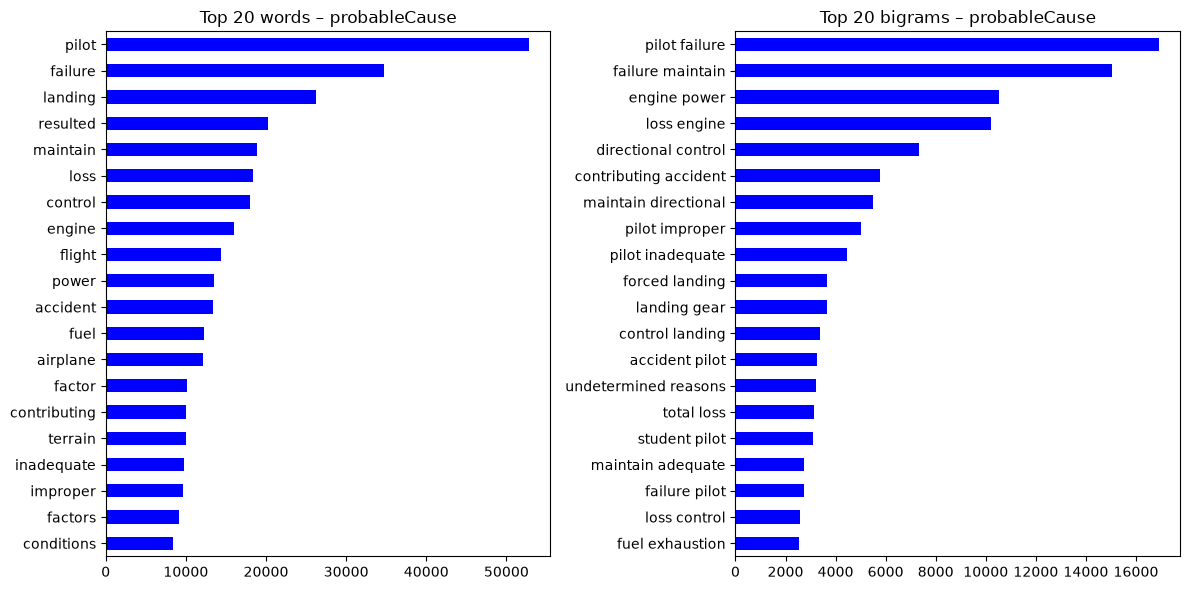

In [88]:
plot_top_terms("probableCause", "blue")

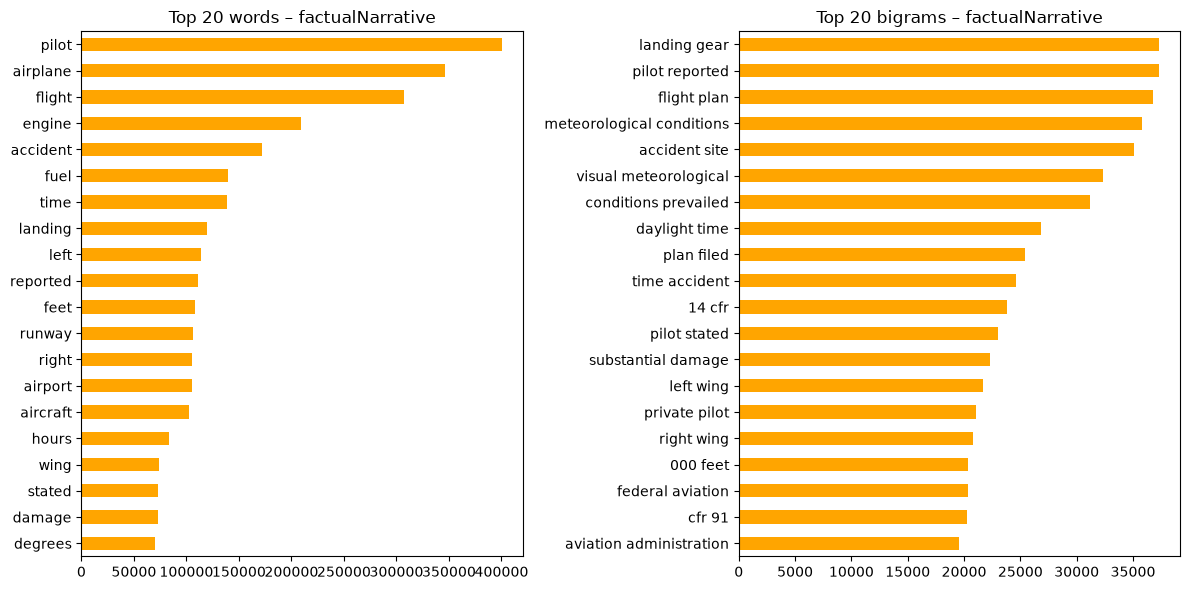

In [89]:
plot_top_terms("factualNarrative", "orange")

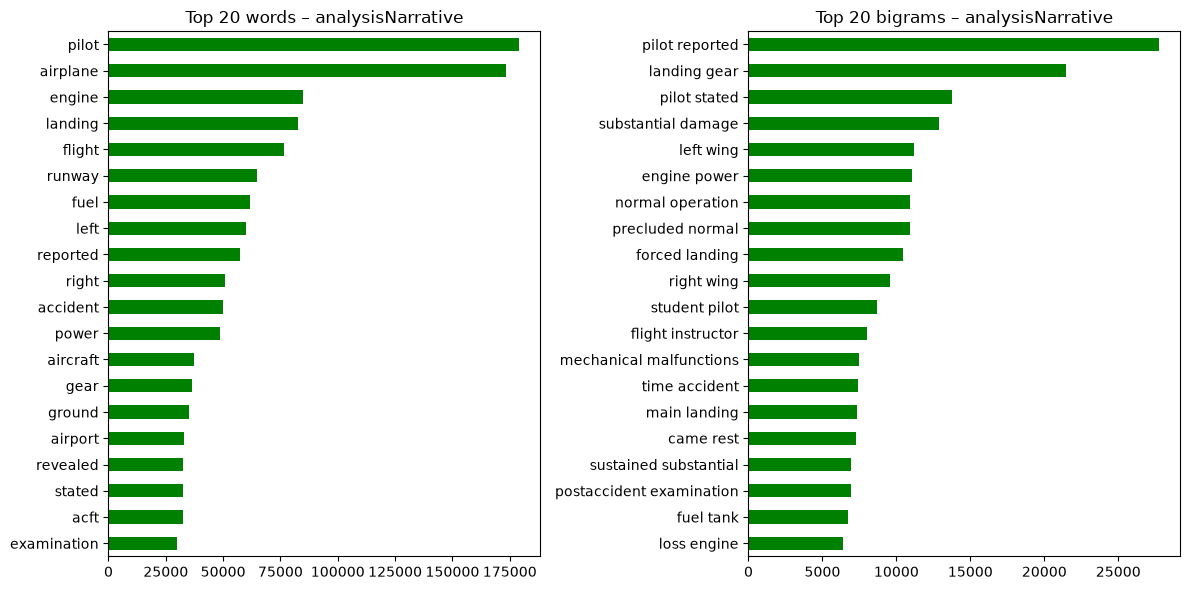

In [90]:
plot_top_terms("analysisNarrative", "green")